In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import GroupKFold, cross_val_score
from src.data_loader import load_split, load_activity_labels
from src.preprocessing import CorrelationFilter
from src.evaluation import evaluate, plot_confusion_matrix

sns.set_theme()
RANDOM_STATE = 42

X_train, y_train, s_train = load_split("train")
X_test, y_test, s_test = load_split("test")
labels = load_activity_labels()
class_ids = sorted(labels)
class_names = [labels[i] for i in class_ids]

print(X_train.shape, X_test.shape)
print(y_test.map(labels).value_counts())

(7352, 561) (2947, 561)
activity_id
LAYING                537
STANDING              532
WALKING               496
SITTING               491
WALKING_UPSTAIRS      471
WALKING_DOWNSTAIRS    420
Name: count, dtype: int64


In [2]:
def make_pipeline(model):
    """Same preprocessing for every model: drop correlated features, scale, then classify."""
    return Pipeline([("corr_filter", CorrelationFilter(0.95)),
                     ("scaler", StandardScaler()),
                     ("model", model)])

models = {
    "Majority-class baseline": Pipeline([("model", DummyClassifier(strategy="most_frequent"))]),
    "Logistic Regression": make_pipeline(LogisticRegression(max_iter=2000)),
    "SVM (RBF)": make_pipeline(SVC()),
}

In [3]:
cv = GroupKFold(n_splits=5)
for name, pipe in models.items():
    scores = cross_val_score(pipe, X_train, y_train, groups=s_train, cv=cv, scoring="accuracy")
    print(f"{name}: CV accuracy {scores.mean():.4f} (std {scores.std():.4f})")

Majority-class baseline: CV accuracy 0.1912 (std 0.0104)
Logistic Regression: CV accuracy 0.9310 (std 0.0331)
SVM (RBF): CV accuracy 0.9209 (std 0.0368)


In [4]:
results = {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    accuracy, per_class, cm, y_pred = evaluate(pipe, X_test, y_test, class_ids, class_names)
    results[name] = {"accuracy": accuracy, "per_class": per_class, "cm": cm, "y_pred": y_pred}
    print(f"{name}: test accuracy = {accuracy:.4f}")

Majority-class baseline: test accuracy = 0.1822
Logistic Regression: test accuracy = 0.9447
SVM (RBF): test accuracy = 0.9494


In [5]:
for name in ["Logistic Regression", "SVM (RBF)"]:
    table = results[name]["per_class"]
    print(name)
    print(table)
    print("macro average:", table[["precision", "recall", "f1"]].mean().round(3).to_dict())
    print()

Logistic Regression
                    precision  recall     f1  support
WALKING                 0.940   0.986  0.963      496
WALKING_UPSTAIRS        0.951   0.938  0.944      471
WALKING_DOWNSTAIRS      0.968   0.926  0.946      420
SITTING                 0.943   0.874  0.907      491
STANDING                0.882   0.951  0.915      532
LAYING                  0.996   0.985  0.991      537
macro average: {'precision': 0.947, 'recall': 0.943, 'f1': 0.944}

SVM (RBF)
                    precision  recall     f1  support
WALKING                 0.958   0.978  0.968      496
WALKING_UPSTAIRS        0.943   0.943  0.943      471
WALKING_DOWNSTAIRS      0.951   0.933  0.942      420
SITTING                 0.932   0.896  0.914      491
STANDING                0.917   0.940  0.929      532
LAYING                  0.993   1.000  0.996      537
macro average: {'precision': 0.949, 'recall': 0.948, 'f1': 0.949}



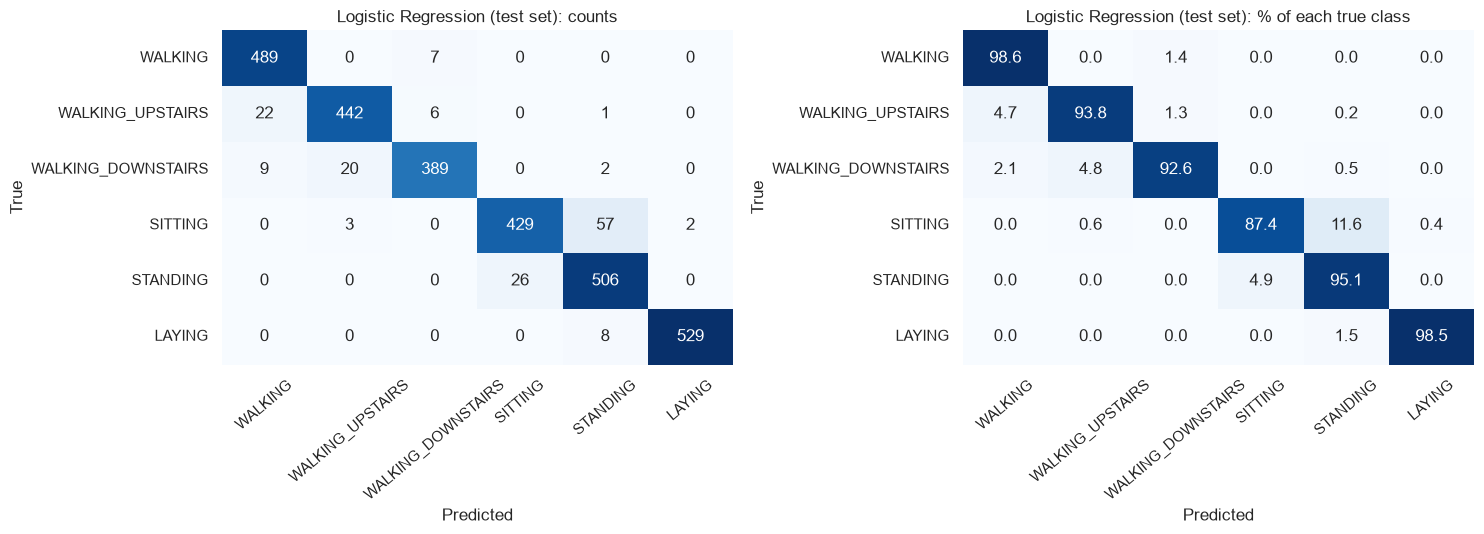

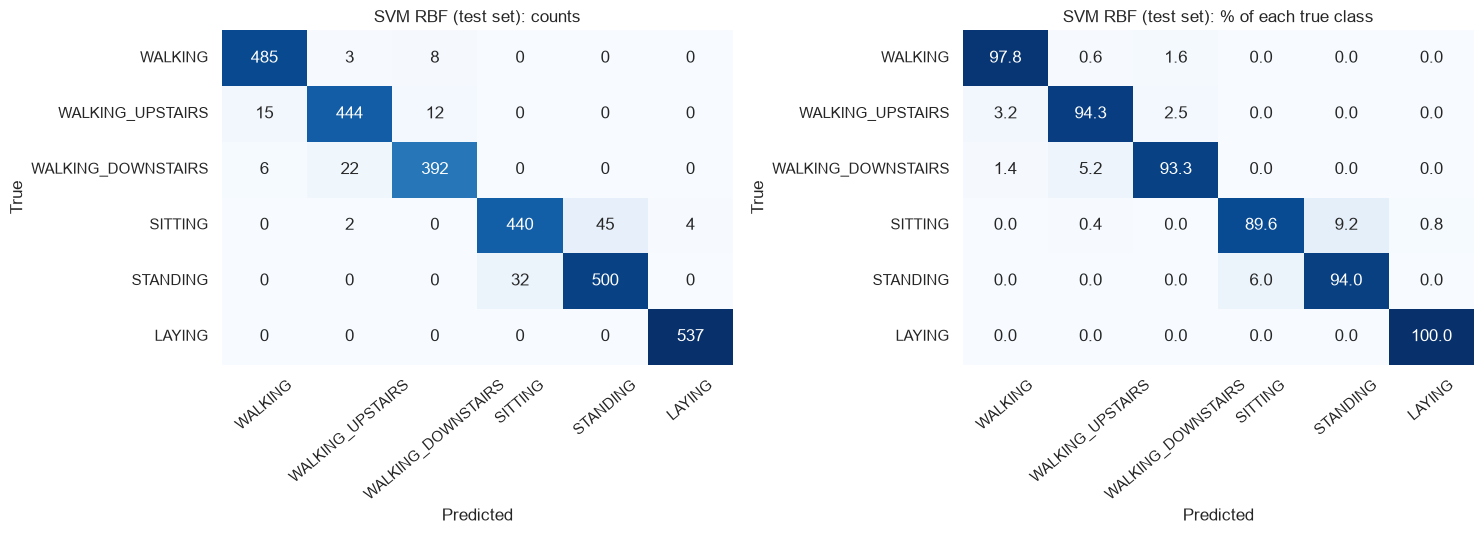

In [6]:
plot_confusion_matrix(results["Logistic Regression"]["cm"], class_names,
                      "Logistic Regression (test set)", "../reports/figures/cm_logreg.png")
plot_confusion_matrix(results["SVM (RBF)"]["cm"], class_names,
                      "SVM RBF (test set)", "../reports/figures/cm_svm.png")

In [7]:
def top_confusions(cm, names, n=5):
    rows = [(names[i], names[j], int(cm[i, j]))
            for i in range(len(names)) for j in range(len(names))
            if i != j and cm[i, j] > 0]
    return (pd.DataFrame(rows, columns=["true", "predicted_as", "count"])
              .sort_values("count", ascending=False).head(n))

i_sit, i_std = class_names.index("SITTING"), class_names.index("STANDING")
for name in ["Logistic Regression", "SVM (RBF)"]:
    cm = results[name]["cm"]
    print(name)
    print(top_confusions(cm, class_names).to_string(index=False))
    print(f"SITTING predicted as STANDING: {cm[i_sit, i_std]} of {cm[i_sit].sum()}")
    print(f"STANDING predicted as SITTING: {cm[i_std, i_sit]} of {cm[i_std].sum()}")
    print()

Logistic Regression
              true     predicted_as  count
           SITTING         STANDING     57
          STANDING          SITTING     26
  WALKING_UPSTAIRS          WALKING     22
WALKING_DOWNSTAIRS WALKING_UPSTAIRS     20
WALKING_DOWNSTAIRS          WALKING      9
SITTING predicted as STANDING: 57 of 491
STANDING predicted as SITTING: 26 of 532

SVM (RBF)
              true       predicted_as  count
           SITTING           STANDING     45
          STANDING            SITTING     32
WALKING_DOWNSTAIRS   WALKING_UPSTAIRS     22
  WALKING_UPSTAIRS            WALKING     15
  WALKING_UPSTAIRS WALKING_DOWNSTAIRS     12
SITTING predicted as STANDING: 45 of 491
STANDING predicted as SITTING: 32 of 532



In [8]:
rows = []
for name in ["Logistic Regression", "SVM (RBF)"]:
    y_pred = results[name]["y_pred"]
    for v in sorted(s_test.unique()):
        mask = (s_test == v).to_numpy()
        rows.append({"model": name, "volunteer": v,
                     "accuracy": round((y_pred[mask] == y_test.to_numpy()[mask]).mean(), 3)})
per_volunteer = pd.DataFrame(rows).pivot(index="volunteer", columns="model", values="accuracy")
print(per_volunteer)
print(per_volunteer.agg(["min", "max", "mean"]).round(3))

model      Logistic Regression  SVM (RBF)
volunteer                                
2                        0.980      0.983
4                        0.946      0.931
9                        0.872      0.865
10                       0.850      0.925
12                       0.944      0.966
13                       0.982      0.979
18                       0.970      0.959
20                       0.944      0.929
24                       0.990      0.992
model  Logistic Regression  SVM (RBF)
min                  0.850      0.865
max                  0.990      0.992
mean                 0.942      0.948


In [9]:
joblib.dump(models["Logistic Regression"], "../models/baseline_logreg.joblib")
joblib.dump(models["SVM (RBF)"], "../models/baseline_svm.joblib")

reloaded = joblib.load("../models/baseline_logreg.joblib")
same = (reloaded.predict(X_test) == results["Logistic Regression"]["y_pred"]).all()
print("Reloaded model gives identical predictions:", same)

Reloaded model gives identical predictions: True
